In [1]:
from scpviz import pAnnData as pAnnData
from scpviz import plotting as scplt
from scpviz import utils as scutils
import scanpy as sc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(context='paper', style='ticks')

import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

g:\Users\marion\miniconda3\envs\scpviz_dev\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
obs_columns = ['sample', 'cellline', 'treatment']

pdata_nb = pAnnData.import_proteomeDiscoverer(prot_file = 'pd_prot.txt', pep_file = 'pd_pep.txt',obs_columns=obs_columns)

🧭 [USER] Importing data of type [pd]
--------------------------
Starting import [Proteome Discoverer]

Source file: pd_prot.txt / pd_pep.txt
Number of files: 12
Proteins: 4988
Peptides: 30920

ℹ️ Using 'Modifications' for modification annotation.

ℹ️ 25 proteins with missing gene names.
     🌐 [API] Querying UniProt for batch 1/1 (25 proteins) [fields: accession, gene_primary]
     ✅ Retrieved UniProt metadata for 25 entries.
     ✅ [OK] Recovered 24 gene name(s) from UniProt. Genes found:
         TUFM, HDLBP, AMPD2, MYG1, HSD17B11, PCM1, NEFH, OXA1L, TRMT5, SLC4A1AP...
     ⚠️ [WARN] 1 gene name(s) still missing. Assigned as 'UNKNOWN_<accession>' for:
         Q6ZSR9
     💡 Tip: You can update these using `pdata.update_identifier_maps({'GENE': 'ACCESSION'}, on='protein', direction='reverse', overwrite=True)`

ℹ️ Removed 64 empty proteins (all-NaN or all-zero). Proteins: P49448, P53675, Q8IZP2, Q15173, O43402, P40123, O95954, O75382, Q9NYQ6, Q14BN4, ...
     ℹ️ [INFO] Using global q-v

     ⚠️ [WARN] `pval` is deprecated in plot_volcano(); use `threshold` instead (applied pval=0.05).
     ⚠️ [WARN] Layer 'X' appears to contain non-log intensities (median=1.56e+06). Statistical tests assume approximately normal distributions — consider log_transform() before DE analysis.
🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: AS_kd vs AS_sc
   🔸 Group sizes: 3 vs 3 samples
   🔸 Layer: X (non-log)
   🔸 Method: ttest | Fold Change: pairwise_median
   🔸 P-value threshold: 0.05 | Log2FC threshold: 1
     ℹ️ [INFO] 434 proteins were not comparable (zero or NaN mean in one group).
     ✅ DE complete. Results stored in:
       • .stats["AS_kd vs AS_sc"]
       • Columns: log2fc, p_value, significance, etc.
       • Upregulated: 20 | Downregulated: 16 | Not significant: 4454 | Not comparable: 434


<Axes: xlabel='$log_{2}$ fold change', ylabel='-$log_{10}$ p value'>

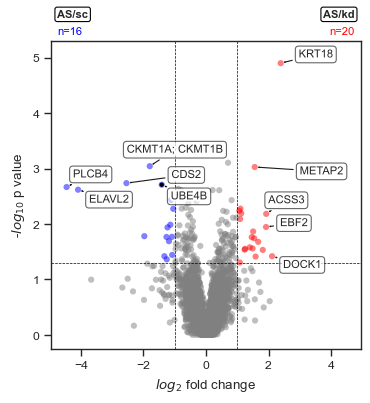

In [3]:
case1 = {'cellline': 'AS', 'treatment': 'kd'}
case2 = {'cellline': 'AS', 'treatment': 'sc'}
case_values = [case1, case2]

fig, ax = plt.subplots(figsize=(4, 4))
ax, volcano_df = scplt.plot_volcano(ax, pdata_nb, values = case_values, pval = 0.05, return_df=True, fold_change_mode='pairwise_median')
ax = scplt.mark_volcano(ax, volcano_df, label=['UBE4B'], label_color="black", show_names=False)
ax
# ax.figure.savefig('AS volcano.png', dpi=300, bbox_inches='tight')
# volcano_df.to_csv('AS volcano.csv')

In [4]:
case1 = {'cellline': 'BE', 'treatment': 'kd'}
case2 = {'cellline': 'BE', 'treatment': 'sc'}
case_values = [case1, case2]

pdata_nb.de(values = case_values, fold_change_mode='pairwise_median')

case1 = {'cellline': 'AS', 'treatment': 'kd'}
case2 = {'cellline': 'BE', 'treatment': 'kd'}
case_values = [case1, case2]

pdata_nb.de(values = case_values, fold_change_mode='pairwise_median')

     ⚠️ [WARN] Layer 'X' appears to contain non-log intensities (median=1.81e+06). Statistical tests assume approximately normal distributions — consider log_transform() before DE analysis.
🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: BE_kd vs BE_sc
   🔸 Group sizes: 3 vs 3 samples
   🔸 Layer: X (non-log)
   🔸 Method: ttest | Fold Change: pairwise_median
   🔸 P-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] 376 proteins were not comparable (zero or NaN mean in one group).
     ✅ DE complete. Results stored in:
       • .stats["BE_kd vs BE_sc"]
       • Columns: log2fc, p_value, significance, etc.
       • Upregulated: 31 | Downregulated: 74 | Not significant: 4443 | Not comparable: 376
     ⚠️ [WARN] Layer 'X' appears to contain non-log intensities (median=1.56e+06). Statistical tests assume approximately normal distributions — consider log_transform() before DE analysis.
🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups

,Genes,AS_kd,BE_kd,log2fc,p_value,test_statistic,-log10(p_value),significance_score,significance
Q9P2X3,IMPACT,4.501726e+05,2.114697e+05,1.156907,0.006955,5.105700,2.157707,2.496266,upregulated
Q8NBJ7,SUMF2,1.942863e+06,7.659381e+05,1.426094,0.011508,4.420364,1.939014,2.765216,upregulated
P08962,CD63,1.117298e+07,2.613840e+06,2.070574,0.003752,6.056121,2.425715,5.022624,upregulated
Q6IBS0,TWF2,1.144725e+07,5.350870e+06,1.105288,0.012327,4.332343,1.909144,2.110154,upregulated
Q9BVC6,TMEM109,5.102196e+06,1.067802e+06,2.308410,0.030270,3.288085,1.518989,3.506449,upregulated
...,...,...,...,...,...,...,...,...,...
P05060,CHGB,NaN,5.512427e+05,NaN,NaN,NaN,NaN,NaN,not comparable
Q14194,CRMP1,NaN,2.498599e+06,NaN,NaN,NaN,NaN,NaN,not comparable
Q9NR33,POLE4,4.029866e+04,2.472978e+05,NaN,0.030707,-5.574347,1.512758,NaN,not comparable
Q10589,BST2,5.075705e+05,NaN,NaN,NaN,NaN,NaN,NaN,not comparable


In [5]:
pdata_nb.list_enrichments()

🧭 [USER] Listing STRING enrichment status

     ℹ️ Available DE comparisons (not yet enriched):
        - AS_kd vs AS_sc
        - AS_kd vs BE_kd
        - BE_kd vs BE_sc

  🔹 To run enrichment:
      pdata.enrichment_functional(from_de=True, de_key="...")

✅ Completed STRING enrichment results:
    (none)

✅ Completed STRING PPI results:
    (none)


In [6]:
genelist = ['P55072', 'NPLOC4', 'UFD1 ', 'STX5A', 'NSFL1C ', 'UBXN2A', 'UBXN4', 'UBE4B', 'YOD1', 'WASHC5','PLAA','UBXN10']

pdata_nb.enrichment_functional(genes=genelist, from_de=False)

🧭 [USER] Running STRING enrichment [user-supplied]
     ℹ️ Found 0 cached STRING IDs. 6 need lookup.
     🌐 [API] UniProt mapped: 6 / 6
          ℹ️ Cached 6 STRING ID mappings.
   🔸 Input genes: 12 → Resolved STRING IDs: 6
   🔸 Species: 9606 | Background: None
     ⚠️ [WARN] Some accessions unresolved: UFD1 , STX5A, NSFL1C , UBXN2A, YOD1, UBXN10
     ✅ [OK] Enrichment complete (1.22s)
   • Access result: pdata.stats['functional']["UserSearch1"]["result"]
   • Plot command : pdata.plot_enrichment_svg("UserSearch1")
   • View online  : https://string-db.org/cgi/network?identifiers=9606.ENSP00000351777%0d9606.ENSP00000331487%0d9606.ENSP00000272638%0d9606.ENSP00000343001%0d9606.ENSP00000318016%0d9606.ENSP00000380460&caller_identity=scpviz&species=9606&show_query_node_labels=1



,category,term,number_of_genes,number_of_genes_in_background,ncbiTaxonId,inputGenes,preferredNames,p_value,fdr,description
0,COMPARTMENTS,GOCC:0034098,2,8,9606,"[9606.ENSP00000331487, 9606.ENSP00000351777]","[NPLOC4, VCP]",2.160000e-06,3.700000e-03,VCP-NPL4-UFD1 AAA ATPase complex
1,Process,GO:0036503,4,93,9606,"[9606.ENSP00000272638, 9606.ENSP00000331487, 9...","[UBXN4, NPLOC4, UBE4B, VCP]",6.930000e-09,8.540000e-05,ERAD pathway
2,Process,GO:0010498,5,462,9606,"[9606.ENSP00000272638, 9606.ENSP00000331487, 9...","[UBXN4, NPLOC4, UBE4B, VCP, PLAA]",4.090000e-08,2.500000e-04,Proteasomal protein catabolic process
3,Process,GO:0043161,4,376,9606,"[9606.ENSP00000331487, 9606.ENSP00000343001, 9...","[NPLOC4, UBE4B, VCP, PLAA]",1.900000e-06,3.900000e-03,Proteasome-mediated ubiquitin-dependent protei...
4,Process,GO:0030970,2,19,9606,"[9606.ENSP00000331487, 9606.ENSP00000351777]","[NPLOC4, VCP]",1.320000e-05,1.250000e-02,"Retrograde protein transport, ER to cytosol"
...,...,...,...,...,...,...,...,...,...,...
107,PMID,PMID:15917639,2,3,9606,"[9606.ENSP00000331487, 9606.ENSP00000351777]","[NPLOC4, VCP]",2.320000e-07,1.130000e-02,(2005) Endoplasmic reticulum-associated protei...
108,PMID,PMID:16234241,2,3,9606,"[9606.ENSP00000331487, 9606.ENSP00000351777]","[NPLOC4, VCP]",2.320000e-07,1.130000e-02,(2005) ATPase activity of p97valosin-containin...
109,RCTM,HSA-110320,2,19,9606,"[9606.ENSP00000331487, 9606.ENSP00000351777]","[NPLOC4, VCP]",1.320000e-05,3.270000e-02,Translesion Synthesis by POLH
110,NetworkNeighborAL,CL:3878,4,24,9606,"[9606.ENSP00000272638, 9606.ENSP00000331487, 9...","[UBXN4, NPLOC4, VCP, PLAA]",2.540000e-11,1.170000e-07,"Mixed, incl. UBX domain, and VCP-NPL4-UFD1 AAA..."


In [ ]:
https://string-db.org/help/api/#linking-to-the-search-results-page

In [8]:
proteins = ["P40925", "P40926"]
df = scutils.get_uniprot_fields(proteins)
df

     🌐 [API] Querying UniProt for batch 1/1 (2 proteins) [fields: accession, id, protein_name, gene_primary, gene_names, organism_id, go, go_f, go_c, go_p, cc_interaction, xref_string]
     ✅ Retrieved UniProt metadata for 2 entries.


,accession,id,protein_names,gene_primary,gene_names,organism_id,gene_ontology_go,gene_ontology_molecular_function,gene_ontology_cellular_component,gene_ontology_biological_process,interacts_with,xref_string
0,P40925,MDHC_HUMAN,"Malate dehydrogenase, cytoplasmic (EC 1.1.1.37...",MDH1,MDH1 MDHA,9606,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,(2R)-hydroxyphenylpyruvate reductase [NAD(P)H]...,cytoplasm [GO:0005737]; cytosol [GO:0005829]; ...,malate metabolic process [GO:0006108]; malate-...,P54274,NaN
1,P40926,MDHM_HUMAN,"Malate dehydrogenase, mitochondrial (EC 1.1.1.37)",MDH2,MDH2,9606,extracellular exosome [GO:0070062]; membrane [...,identical protein binding [GO:0042802]; L-mala...,extracellular exosome [GO:0070062]; membrane [...,aerobic respiration [GO:0009060]; gluconeogene...,NaN,9606.ENSP00000327070
